In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob

from itertools import combinations
import sys
from statsmodels.stats.multitest import multipletests
from scipy.stats import norm
import os
import pickle

In [2]:
import helper_functions as hf

In [3]:
plt.rcParams.update({'font.size': 14})

# NMD escape features

In [4]:
%%time
import pyranges as pr
gtf = pr.read_gtf('./gtfs/ensembl_filtered.gtf').df

CPU times: total: 1min 3s
Wall time: 1min 3s


In [5]:
import nmd_features as nf

In [6]:
catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')
cat = catalog[['src','event_id','nmd_id_list']].drop_duplicates()

In [7]:
trids = []
for _,row in cat.iterrows():
    trs = row.nmd_id_list.split(', ')
    for tr in trs:
        row.nmd_id_list = tr
        trids.append(row.copy())

trids = pd.concat(trids,axis=1).T.rename(columns={'nmd_id_list':'transcript_id'})

In [8]:
trids = trids[trids.transcript_id.str.startswith('ENST')]

In [9]:
fgtf = gtf[gtf.transcript_id.isin(trids.transcript_id)]

In [10]:
%%time
from Bio import SeqIO
fasta_path = "C:/Users/zavil/arkuda_backup/genomes/GRCh38/GRCh38.fa"
hg38 = SeqIO.to_dict(SeqIO.parse(fasta_path,'fasta'))

CPU times: total: 25.4 s
Wall time: 40.9 s


In [11]:
hg38 = {key:val.seq for key,val in hg38.items()}

In [12]:
from importlib import reload
reload(nf)

<module 'nmd_features' from 'C:\\Users\\zavil\\tcga_paper\\NMDeq\\nmd_psi\\nmd_features.py'>

In [13]:
exclude = {'ENST00000494537','ENST00000648872','ENST00000519214'}
trset = list(set(trids.transcript_id)-exclude)

In [14]:
trids.shape

(13214, 3)

In [15]:
%%time
res = nf.extract_features(fgtf,hg38,trids.transcript_id)

ENST00000494537: annotated stop=1464 nt, translated first stop=1281 nt
ENST00000648872: annotated stop=378 nt, translated first stop=285 nt
ENST00000519214: annotated stop=189 nt, translated first stop=129 nt
ENST00000553522: annotated stop=234 nt, translated first stop=117 nt
ENST00000557323: annotated stop=234 nt, translated first stop=117 nt
ENST00000599874: annotated stop=255 nt, translated first stop=54 nt
CPU times: total: 2min 40s
Wall time: 2min 41s


In [16]:
res.isna().mean()

transcript_id             0.000000
stop_to_exon5             0.000000
stop_to_exon3             0.000000
stop_to_start             0.000000
stop_to_downstream_AUG    0.334419
dtype: float64

In [17]:
res.stop_to_downstream_AUG = res.stop_to_downstream_AUG.replace(pd.NA,np.inf).astype(float)

In [18]:
trids = trids.merge(res)

In [19]:
trids.transcript_id.nunique(),trids.event_id.nunique()

(13208, 10818)

In [20]:
trids = trids.groupby(['src', 'event_id', 'stop_to_exon5', 
                       'stop_to_exon3', 'stop_to_start', 
                       'stop_to_downstream_AUG']).transcript_id.agg(list).apply(lambda x: ", ".join(sorted(x))).reset_index()

In [21]:
aa= trids.event_id.value_counts()
ind = aa[aa==6].index
trids[trids.event_id.isin(ind)]

,src,event_id,stop_to_exon5,stop_to_exon3,stop_to_start,stop_to_downstream_AUG,transcript_id
2654,ensembl,ENSG00000116337_2,23,108,114,355.0,"ENST00000679379, ENST00000680929, ENST00000681108"
2655,ensembl,ENSG00000116337_2,23,108,114,501.0,ENST00000681862
2656,ensembl,ENSG00000116337_2,23,108,114,693.0,ENST00000681132
2657,ensembl,ENSG00000116337_2,23,108,114,1515.0,ENST00000680820
2658,ensembl,ENSG00000116337_2,23,108,114,1665.0,ENST00000652975
2659,ensembl,ENSG00000116337_2,23,108,114,1692.0,ENST00000680148
3874,ensembl,ENSG00000135317_0,35,311,2529,401.0,ENST00000682633
3875,ensembl,ENSG00000135317_0,35,311,2532,401.0,ENST00000684299
3876,ensembl,ENSG00000135317_0,35,311,2556,401.0,ENST00000683577
3877,ensembl,ENSG00000135317_0,35,311,2685,401.0,ENST00000682133


In [22]:
responder_df = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_responder_prob_anno.tsv',sep='\t')
responder_df['responder'] = np.where(responder_df.prob>0.5,1,0)
responder_df.groupby('experiment').responder.agg('mean')

experiment
HCT116 UPF1 KD     0.679255
HeLa CHX           0.717325
HeLa SMG6 KD       0.799719
HeLa UPF1 KD       0.704225
HeLa dKD           0.691308
HepG2 nucl/cyto    0.736121
K562 nucl/cyto     0.692308
Name: responder, dtype: float64

In [23]:
responder_df['gamma'] = hf.psir2gamma(responder_df.ctrl_psi,responder_df.exp_psi)

In [24]:
Y = responder_df[responder_df.experiment=='HeLa dKD'][['src','event_id','gamma','responder','prob']]
data = Y.merge(trids)

In [25]:
data.stop_to_downstream_AUG = np.where(data.stop_to_downstream_AUG>1000,1000,data.stop_to_downstream_AUG)

In [26]:
data.event_id.value_counts().value_counts()

count
1    1769
2     205
3      43
4      13
5       4
6       1
Name: count, dtype: int64

In [27]:
aa= trids.event_id.value_counts()
ind = aa[aa==6].index
trids[trids.event_id.isin(ind)]

,src,event_id,stop_to_exon5,stop_to_exon3,stop_to_start,stop_to_downstream_AUG,transcript_id
2654,ensembl,ENSG00000116337_2,23,108,114,355.0,"ENST00000679379, ENST00000680929, ENST00000681108"
2655,ensembl,ENSG00000116337_2,23,108,114,501.0,ENST00000681862
2656,ensembl,ENSG00000116337_2,23,108,114,693.0,ENST00000681132
2657,ensembl,ENSG00000116337_2,23,108,114,1515.0,ENST00000680820
2658,ensembl,ENSG00000116337_2,23,108,114,1665.0,ENST00000652975
2659,ensembl,ENSG00000116337_2,23,108,114,1692.0,ENST00000680148
3874,ensembl,ENSG00000135317_0,35,311,2529,401.0,ENST00000682633
3875,ensembl,ENSG00000135317_0,35,311,2532,401.0,ENST00000684299
3876,ensembl,ENSG00000135317_0,35,311,2556,401.0,ENST00000683577
3877,ensembl,ENSG00000135317_0,35,311,2685,401.0,ENST00000682133


In [28]:
np.isfinite(data.gamma).value_counts()

gamma
True     2382
False       4
Name: count, dtype: int64

In [29]:
data = data[np.isfinite(data.gamma)].copy()

In [30]:
data['exon_length'] = data.stop_to_exon5+data.stop_to_exon3

In [31]:
feature_cols = ['stop_to_exon5', 'stop_to_exon3', 'exon_length', 'stop_to_start', 'stop_to_downstream_AUG']

# Random forest hyperparameters

In [32]:
from scipy.stats import spearmanr

from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.model_selection import (
    StratifiedKFold,
    KFold,
    RandomizedSearchCV,
)
from sklearn.metrics import make_scorer
from scipy.stats import spearmanr


# ------------------------------------------------------------
# Spearman scorer for gamma
# ------------------------------------------------------------

def spearman_score(y_true, y_pred):
    return spearmanr(y_true, y_pred).statistic


spearman_scorer = make_scorer(
    spearman_score,
    greater_is_better=True,
)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

X = data[feature_cols]
y = data['responder']

rf_clf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

param_grid_clf = {
    "n_estimators": [500, 1000, 2000],
    "max_depth": [None, 10, 20, 50],
    "min_samples_leaf": [1, 2, 5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "max_features": [0.3, 0.5, 1.0],
}

cv_clf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_clf = GridSearchCV(
    estimator=rf_clf,
    param_grid=param_grid_clf,
    scoring="roc_auc",
    cv=cv_clf,
    n_jobs=-1,
    refit=True,
    verbose=1,
    return_train_score=True
)

grid_clf.fit(X, y)

print("Best parameters:")
print(grid_clf.best_params_)

print("Best CV ROC-AUC:")
print(grid_clf.best_score_)

Fitting 5 folds for each of 540 candidates, totalling 2700 fits


In [ ]:
clf_cv = (
    pd.DataFrame(grid_clf.cv_results_)
    .sort_values("rank_test_score")
)

clf_cv[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "param_n_estimators",
        "param_max_depth",
        "param_min_samples_leaf",
        "param_min_samples_split",
        "param_max_features",
    ]
].head(15)

In [ ]:
clf_selected_params = grid_clf.best_params_

# Random forest feature importance

In [ ]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import StratifiedKFold, RepeatedKFold
from sklearn.metrics import roc_auc_score, mean_absolute_error


def permutation_feature_importance_rf(
    df,
    feature_cols,
    target,
    task="classification",
    n_splits=5,
    n_repeats_cv=5,
    n_permutations=10,
    random_state=42,
    n_estimators=1000,
    max_features="sqrt",
    min_samples_leaf=2,
    n_jobs=-1,
):
    """
    Permutation feature importance for Random Forest.

    Classification:
        metric = ROC-AUC

    Regression:
        metric = -MAE

    Importance:
        baseline_score - score_after_permutation

    Positive importance:
        permutation ухудшает prediction -> feature полезна.

    Negative importance:
        permutation случайно улучшила prediction.
    """

    X = df[feature_cols].copy()
    y = df[target].copy()

    rng = np.random.default_rng(random_state)

    # ---------------------------------------------------------
    # Cross-validation
    # ---------------------------------------------------------

    if task == "classification":

        cv = StratifiedKFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=random_state,
        )

    elif task == "regression":

        cv = RepeatedKFold(
            n_splits=n_splits,
            n_repeats=n_repeats_cv,
            random_state=random_state,
        )

    else:
        raise ValueError(
            "task must be 'classification' or 'regression'"
        )

    records = []

    # ---------------------------------------------------------
    # CV
    # ---------------------------------------------------------

    for fold, (train_idx, test_idx) in enumerate(cv.split(X, y)):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        # -----------------------------------------------------
        # Train full model
        # -----------------------------------------------------

        if task == "classification":

            model = RandomForestClassifier(
                **clf_selected_params,
                class_weight="balanced",
                random_state=random_state + fold,
                n_jobs=n_jobs,
            )

        else:

            model = RandomForestRegressor(
                **reg_selected_params,
                random_state=random_state + fold,
                n_jobs=n_jobs,
            )

        model.fit(X_train, y_train)

        # -----------------------------------------------------
        # Baseline prediction
        # -----------------------------------------------------

        if task == "classification":

            baseline_pred = model.predict_proba(X_test)[:, 1]

            baseline_score = roc_auc_score(
                y_test,
                baseline_pred,
            )

        else:

#            baseline_pred = model.predict(X_test)
#
#            baseline_score = -mean_absolute_error(
#                y_test,
#                baseline_pred,
#            )
            baseline_pred = model.predict(X_test)
            
            baseline_score = spearmanr(
                y_test,
                baseline_pred,
            ).statistic

        # -----------------------------------------------------
        # Permute every feature
        # -----------------------------------------------------

        for feature in feature_cols:

            for permutation in range(n_permutations):

                X_perm = X_test.copy()

                # независимая перестановка фичи
                shuffled = X_perm[feature].to_numpy().copy()
                rng.shuffle(shuffled)

                X_perm[feature] = shuffled

                # -------------------------------------------------
                # Prediction after permutation
                # -------------------------------------------------

                if task == "classification":

                    perm_pred = model.predict_proba(
                        X_perm
                    )[:, 1]

                    perm_score = roc_auc_score(
                        y_test,
                        perm_pred,
                    )

                else:

                    perm_pred = model.predict(X_perm)

#                    perm_score = -mean_absolute_error(
#                        y_test,
#                        perm_pred,
#                    )

                    perm_score = spearmanr(
                        y_test,
                        perm_pred,
                    ).statistic

                # -------------------------------------------------
                # Importance
                # -------------------------------------------------

                importance = baseline_score - perm_score

                records.append({
                    "fold": fold,
                    "permutation": permutation,
                    "feature": feature,
                    "baseline_score": baseline_score,
                    "permuted_score": perm_score,
                    "importance": importance,
                })

    results = pd.DataFrame(records)

    # ---------------------------------------------------------
    # Summary
    # ---------------------------------------------------------

    summary = (
        results
        .groupby("feature")
        .agg(
            importance_mean=("importance", "mean"),
            importance_std=("importance", "std"),
            importance_median=("importance", "median"),
            baseline_score_mean=("baseline_score", "mean"),
            permuted_score_mean=("permuted_score", "mean"),
        )
        .sort_values(
            "importance_mean",
            ascending=False,
        )
    )


    return results, summary

In [37]:
%%time
clf_results, clf_importance = permutation_feature_importance_rf(
    df=data,
    feature_cols=feature_cols,
    target="responder",
    task="classification",
    n_splits=5,
    n_repeats_cv=5,
    n_permutations=10,
    random_state=42,
)

clf_importance

CPU times: total: 49 s
Wall time: 36.3 s


,importance_mean,importance_std,importance_median,baseline_score_mean,permuted_score_mean
feature,,,,,
stop_to_start,0.088707,0.023701,0.086746,0.646798,0.558091
exon_length,0.032640,0.016442,0.033369,0.646798,0.614158
stop_to_exon3,0.032228,0.019045,0.032925,0.646798,0.614571
stop_to_exon5,0.022951,0.014883,0.021182,0.646798,0.623848
stop_to_downstream_AUG,0.017541,0.020558,0.018125,0.646798,0.629258


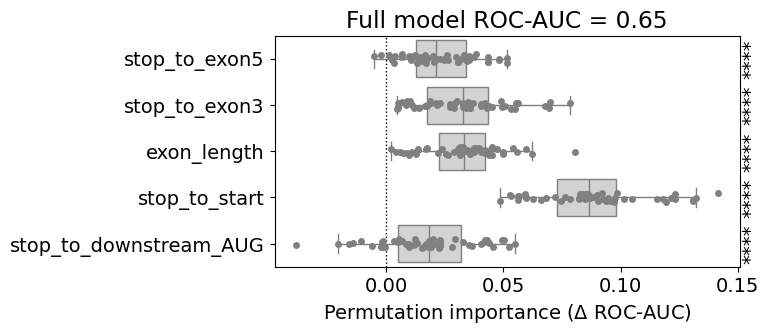

In [38]:
from scipy.stats import wilcoxon
f,ax = plt.subplots(figsize=(6,3))
sns.boxplot(data=clf_results,x='importance',y='feature',color='lightgrey',showfliers=False)
sns.stripplot(data=clf_results,x='importance',y='feature',color='grey')
ax.set_xlabel(r'Permutation importance ($\Delta$ ROC-AUC)')
ax.set_ylabel(None)
ax.set_title(f'Full model ROC-AUC = {clf_results.baseline_score.mean():.2f}')

features = clf_results['feature'].unique()

pvals = []
for feature in features:
    x = clf_results.loc[
        clf_results['feature'] == feature,
        'importance'
    ].dropna()

    _, p = wilcoxon(x)
    pvals.append(p)

# BH correction
_, pvals_adj, _, _ = multipletests(
    pvals,
    method='fdr_bh'
)

# добавить p-values справа от boxplot
xmax = clf_results['importance'].max()
offset = (clf_results['importance'].max()
          - clf_results['importance'].min()) * 0.053

for feature, p in zip(features, pvals_adj):
    y = list(features).index(feature)

    ax.text(
        xmax+offset,
        y,
        hf.p2star(p),
        va='center',
        rotation=90
    )

ax.axvline(0,lw=1,ls=':',c='black')

In [41]:
f.savefig('./figures/SF7.pdf',bbox_inches='tight')